# Lab 02 - Road Lines and Street Signs Detection with the Hough Transform

Computer Vision 2024-25 (M. Caligiuri, P. Zanuttigh, F. Barbato and F. Lincetto)

In this lab you will explore the topic of line and circle detection using the Hough transform. In particular you will use this technique to detect the street lanes and the round street signs in the provided images.

---

## Import the necessary libraries

In [1]:
# Import the necessary packages
%matplotlib inline

import typing as tp
import numpy as np
import cv2 as cv
from matplotlib import pyplot as plt

---

## Define some auxiliary functions

Write here all the auxiliary functions you will need.
More precisely you have to implement the following functions:
- `show_img` -> given in input an image and (optionally) a title it will plot the image as a matplotlib plot performing also the necessary conversion from BGR to RGB,
- `polar2cartesian` -> given an array of angles and one of radii it will return an array containing the corresponding cartesian coordinates (x,y), and an array containing the line direction (i.e., $\left[sin(\theta), -cos(\theta)\right]$)
- `draw_lines` -> given in input an image and a set of lines it will draw the lines on the image and return the resulting image,
- `fill_lines` -> given in input an image and the mask of the lines it will fill the lines with a given color and return the resulting image.

In [2]:
# Function to plot images inline in the notebook
def show_img(img, title=None):
    # Check if the image is in BGR format and convert it to RGB
    if len(img.shape) == 3 and img.shape[2] == 3:
        img = cv.cvtColor(img, cv.COLOR_BGR2RGB)

    # Plot the image
    plt.figure() 
    plt.imshow(img)
    if title:
        plt.title(title)
    plt.axis('off')
    plt.tight_layout()
    plt.show()
    plt.close()

In [3]:
# Function to perform the conversion between polar and cartesian coordinates
def polar2cartesian(radius: np.ndarray, angle: np.ndarray) -> tp.Tuple[np.ndarray]:
    return radius * np.array([np.cos(angle), np.sin(angle)]), np.array([np.sin(angle), -np.cos(angle)])

In [4]:
# Funtion to add lines to an image
def draw_lines(img: np.ndarray, lines: np.ndarray, color: tp.List[int] = [0, 0, 255], thickness: int = 1) -> tp.Tuple[np.ndarray]:
    new_image = np.copy(img)
    empty_image = np.zeros(img.shape[:2])

    if len(lines.shape) == 1:
        lines = lines[None, ...]

    # Draw found lines
    for rho, theta in lines:
        cx, direction = polar2cartesian(rho, theta)
        pt1 = np.round(cx + 10000*direction).astype(int)
        pt2 = np.round(cx - 10000*direction).astype(int)
        empty_image = cv.line(img=empty_image,pt1=pt1, pt2=pt2, color=255, thickness=thickness)

    # Keep lower part of each line until intersection
    mask_lines = empty_image != 0
    max_line = 0
    valid = flag = False # check that we found 2 lines at least once before 
    for i, line in enumerate(mask_lines): # iterate each line and search for a batch of contiguous idxs
        indices = np.argwhere(line)
        if len(indices) > 1:
            flag = True
            for ii in range(len(indices)-1):
                flag = flag and indices[ii+1] == indices[ii] + 1
                if not flag:
                    valid = True 
                    break
                if valid:
                    max_line = i
        elif len(indices) == 1 and valid:
            max_line = i
        if flag and valid:
            break

    mask_boundaries = np.zeros_like(empty_image)
    mask_boundaries[max_line:] = 1
    mask = (mask_lines * mask_boundaries).astype(bool)

    new_image[mask_lines] = np.array(color)
    
    return new_image, mask

In [5]:
# Function that given the image and the mask of the lines, fill the area between the lines
def fill_lines(img: np.ndarray, mask: np.ndarray, color: tp.List[int] = [0, 0, 255]) -> np.ndarray:
    border = np.where(mask)

    possible_vertex = np.where(border[0] == np.min(border[0]))
    vertex = np.array([border[0][int(len(possible_vertex[0]) / 2)], border[1][int(len(possible_vertex[0]) / 2)]])[::-1]

    possible_bottom = np.where(border[0] == np.max(border[0]))
    bottom_pos = [np.min(possible_bottom[0]), np.max(possible_bottom[0])]
    bottom_left = np.array([border[0][bottom_pos[0]], border[1][bottom_pos[0]]])[::-1]
    bottom_right = np.array([border[0][bottom_pos[1]], border[1][bottom_pos[1]]])[::-1]
    points = np.array([vertex, bottom_left, bottom_right])

    return cv.fillConvexPoly(np.copy(img), points=points, color=color)

---

## Road lines Detection

In this section you have to implement the road detection using the Hough transform together with the Canny algorithm.

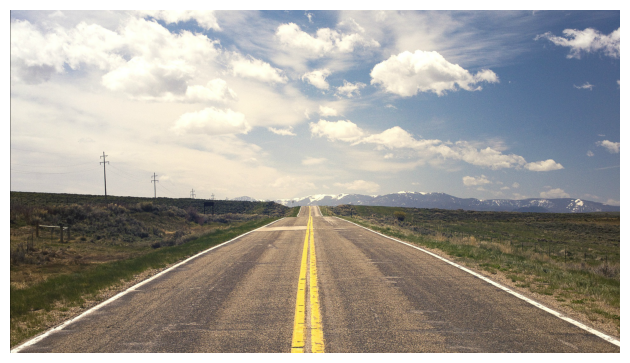

In [6]:
# Load image (img path './data/road2.png')
image = cv.imread('./data/road2.png')

# Show the image
show_img(image)

### Edge extraction using the Canny algorithm

In [15]:
# Create a cv window with two trackbars to change the thresholds values of the Canny algorithm
# Choose the best threshols values to extract the edges of the road
# It is suggested, but not mandatory, to use trackbars to find the best values interactively
# Print also the best parameters

# Define the name of the window
window_name = 'Canny Thresholds'

# Define the name of the trackbars
trackbar_name1 = 'Threshold 1'
trackbar_name2 = 'Threshold 2'

# Define the initial values of the trackbars
threshold1 = 25
threshold2 = 75

# Function to update the image
def update_image(val):
    # Get the values of the trackbars
    threshold1 = cv.getTrackbarPos(trackbar_name1, window_name)
    threshold2 = cv.getTrackbarPos(trackbar_name2, window_name)
    
    # Apply the Canny algorithm
    edges = cv.Canny(image, threshold1*10, threshold2*10, apertureSize = 3)
    
    # Show the image
    cv.imshow(window_name, edges)

# Create the window
cv.namedWindow(window_name, cv.WINDOW_GUI_NORMAL)

# Create the trackbars
cv.createTrackbar(trackbar_name1, window_name, threshold1, 100, update_image)
cv.createTrackbar(trackbar_name2, window_name, threshold2, 100, update_image)

# Show the window
cv.waitKey(0)
cv.destroyAllWindows()

error: OpenCV(4.10.0) D:\a\opencv-python\opencv-python\opencv\modules\highgui\src\window.cpp:868: error: (-215:Assertion failed) trackbar in function 'cv::getTrackbarPos'


In [ ]:
# Visualize the result of the Canny algorithm with the best thresholds values
# Suggestions: use the function show_img() and check that the edges are suitable for the next step (see the example on the slides)
# ADD YOUR CODE HERE

### Hough transform to detect lines

In [2]:
# Create a window with a set of trackbars to change the parameters of the Hough transform
# Choose the best parameters to find the lines of the road
# It is suggested, but not mandatory, to use trackbars to find the best values interactively
# ADD YOUR CODE HERE

In [ ]:
# Visualize the result of the Hough transform with the best parameters
# ADD YOUR CODE HERE

# Color all the pixels inside the lines in red (you can use the provided fill_lines function)
# ADD YOUR CODE HERE

### Custom implementation of the Hough transform

Now try to implement the Hough transform by yourself. You can use the following steps as a guide:
1. Use provided rho (spatial delta), theta (angle delta), min_theta and max_theta parameters to compute the discretized parameter space (i.e. the accumulator) dimensions (2D x T), where $D = \sqrt{W^2 +  H^2}$
2. Create the accumulator as a numpy array and initialize it to zero,
3. For each edge point in the image:
    - For each angle in the discretization:
        1. Compute the corresponding radius -- note that the radius can be negative (you can map the 0 to 2D-1 indexes to [-D,D] )
        2. Increment the accumulator at the corresponding position,
4. Find the points in the accumulator with count > threshold,
5. Compute the corresponding angle and radius of each found point,
6. Return the line corresponding to the angle and radius.

In [ ]:
# Define a function to perform the Hough transform and return the lines found
def hough_lines(edges: np.ndarray, rho: float, theta: float, threshold: float, min_theta: float, max_theta: float) -> np.ndarray:
    # Initialize the counter matrix in polar coords
    # ADD YOUR CODE HERE

    # Define angular step
    # ADD YOUR CODE HERE

    # Consider edges only
    # ADD YOUR CODE HERE

    # Update the counter
    # ADD YOUR CODE HERE

    # Take the polar coords most matched
    # ADD YOUR CODE HERE

    pass

In [ ]:
# Use the function to find the lines in the image
# ADD YOUR CODE HERE

# Show the image with the lines found
# Suggestions: use the function fill_lines() and show_img()
# ADD YOUR CODE HERE

---

## Road signs detection using the Hough transform

In this section you will implement the road signs detection using again the Hough transform.

**N.B.** You can use the `cv.HoughCircles()` function (keep in mind that this function includes the edge extraction). Here no need to implement the Hough transform manually, just use openCV in this point.

**N.B.** You can use the `cv.circle()` function to draw the circles on the image (set thickness = -1 to fill the circles).

In [ ]:
# Convert the image to uint8 for the Hough transform algorithm
# ADD YOUR CODE HERE

# Choose the best parameters to find all the circle sign in the image
# It is suggested, but not mandatory, to use trackbars to find the best values interactively
# ADD YOUR CODE HERE

In [ ]:
# Visualize the result of the Hough transform with the best parameters
# ADD YOUR CODE HERE